# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [2]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

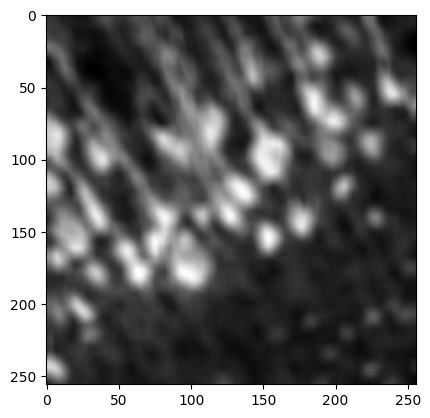

In [5]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

conv_img = conv(img, psf, mode ="same", boundary = "symm")
plt.imshow(conv_img, "gray")

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

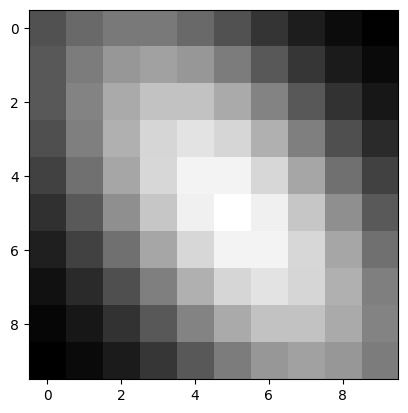

In [6]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

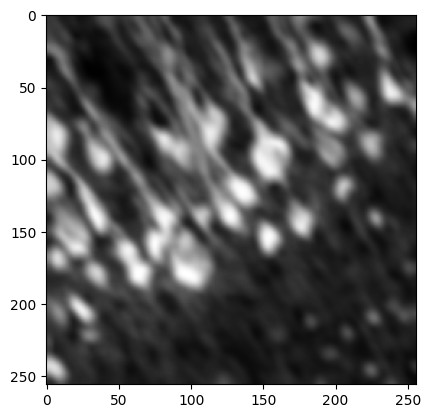

In [8]:
convgauss_img = conv(img, create_psf(psf_size), mode ="same", boundary = "symm")
plt.imshow(convgauss_img, "gray")

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [9]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    psf_flipped = np.flip(psf)

    for t in range(n_iterations):
        blurred = conv(img_deconv, psf, mode= "same", boundary="symm")
        ratio = image/blurred
        correction = conv(ratio, psf_flipped, mode="same", boundary="symm")
        img_deconv = img_deconv * correction
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [30]:
restored_img = richardson_lucy_deconvolution(conv_img, psf, 20)



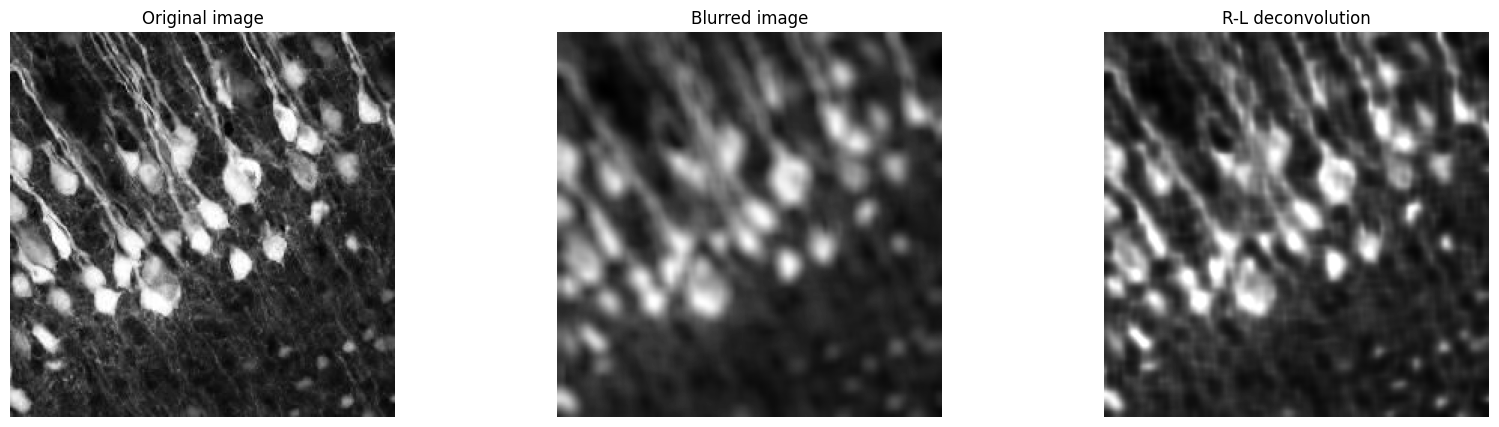

In [31]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(conv_img, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(restored_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [26]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

noise_image = np.clip(convgauss_img + noise, 0, 1)


In [27]:
restored_noiseimg = richardson_lucy_deconvolution(noise_image, psf, 20)

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

Text(0.5, 1.0, 'Noise Image')

<Figure size 2000x500 with 0 Axes>

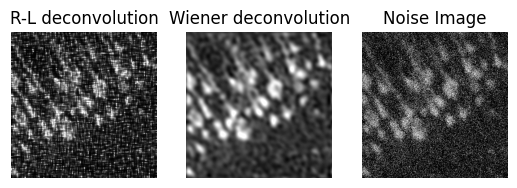

In [29]:
wiener_deconv = wiener(noise_image, create_psf(psf_size), balance =2, clip=True)

plt.figure(figsize=(20,5))
plt.figure()
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(restored_noiseimg, 'gray')
plt.title('R-L deconvolution')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(wiener_deconv, 'gray')
plt.title('Wiener deconvolution')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(noise_image, 'gray')
plt.title('Noise Image')

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

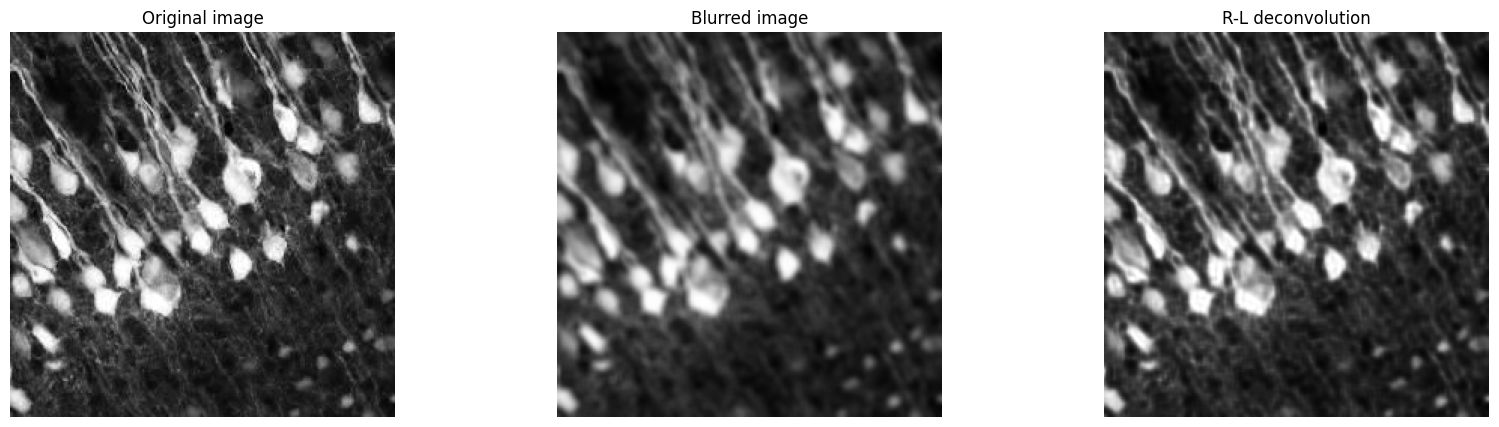

Text(0.5, 1.0, 'Noise Image')

<Figure size 2000x500 with 0 Axes>

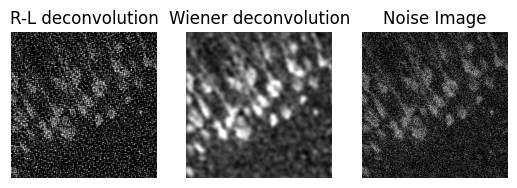

In [32]:
psf_size = 5
psf = np.ones((psf_size, psf_size)) / psf_size ** 2
psf_gauss = create_psf(psf_size)

conv_img = conv(img, psf, mode ="same", boundary = "symm")
convgauss_img = conv(img, psf_gauss, mode ="same", boundary = "symm")

restored_img = richardson_lucy_deconvolution(conv_img, psf, 20)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(conv_img, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(restored_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

noise_image = np.clip(convgauss_img + noise, 0, 1)

restored_noiseimg = richardson_lucy_deconvolution(noise_image, psf, 20)

wiener_deconv = wiener(noise_image, create_psf(psf_size), balance =2, clip=True)

plt.figure(figsize=(20,5))
plt.figure()
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(restored_noiseimg, 'gray')
plt.title('R-L deconvolution')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(wiener_deconv, 'gray')
plt.title('Wiener deconvolution')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(noise_image, 'gray')
plt.title('Noise Image')


**[Task 8.]()** Use a wrong PSF to restore the image

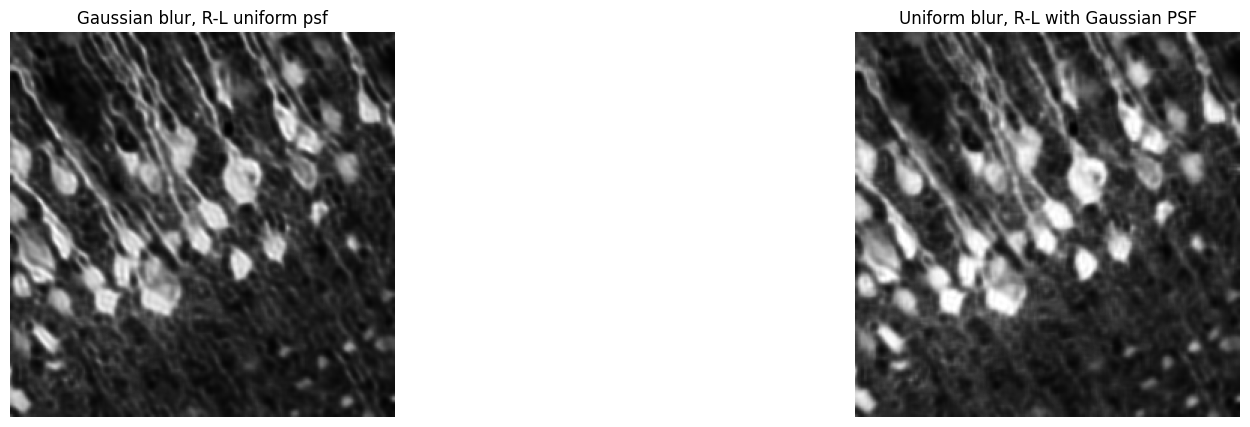

In [33]:
wrong_gauss = richardson_lucy_deconvolution(convgauss_img, psf, 20)
wrong_uni = richardson_lucy_deconvolution(conv_img, psf_gauss, 20)

plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(wrong_gauss, 'gray')
plt.title('Gaussian blur, R-L uniform psf')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(wrong_uni, 'gray')
plt.title('Uniform blur, R-L with Gaussian PSF')
plt.show()